# Thực nghiệm quản lý kho thông minh với MCP C# SDK

**Notebook:** `MCP_CSharp_Inventory_Experiments.ipynb` · **Đề tài:** MCP.2505 — Model Context Protocol, C# SDK.

Notebook gồm hai phần có nguồn dữ liệu và log riêng:

- **A — Training/Validation/Test:** mô hình phụ TF-IDF + softmax phân loại câu hỏi tiếng Việt thành 8 read tool MCP. C# thực hiện huấn luyện thực; Python điều phối, hiển thị bảng và biểu đồ. Dataset 160 câu mẫu được biên soạn cho bài, chưa phải hội thoại người dùng thực tế. Đây không phải fine-tuning LLM hoặc huấn luyện giao thức MCP.
- **B — MCP/PostgreSQL thật:** đọc snapshot SQL, chạy 10 cấu hình tool, so sánh input/output và thực thi các tool do mô hình dự đoán. API và MCP đều là ứng dụng C# hiện có. Không ghi tồn kho từ notebook.

## Cách chạy đầy đủ, không phải nhập DB thủ công

Từ thư mục gốc dự án (PostgreSQL đã chạy, User Secrets của API hợp lệ và account DB có quyền tạo DB test):

```sh
dotnet build AI-Smart-Inventory.slnx --disable-build-servers
INVENTORY_NOTEBOOK_QA=1 dotnet run --project experiments/Verification --no-build
```

Harness C# tạo DB test riêng, migrate/seed dữ liệu, chạy API/MCP, thực thi notebook và tự dọn DB đó. Output được lưu vào notebook. Chế độ này không gọi provider LLM và không gửi dữ liệu ra ngoài.

## Chạy thủ công trong VS Code/Jupyter

Chọn kernel có pandas, matplotlib, psycopg, nbformat/nbclient nếu dùng runner. Run All bắt đầu Training mà không cần DB. Để chạy phần B, bật API/MCP và nhập đúng host/port/database/username/password PostgreSQL cùng tài khoản ứng dụng Admin/Staff. SQL/API/MCP phải dùng cùng DB/schema. Không nhập tên DB chưa tồn tại; không thay tên trong ô nhập để giả định đã tạo DB.

Mật khẩu nhập ẩn; không ghi credentials/JWT vào notebook. Dữ liệu kho dùng cho bài là dữ liệu mẫu lưu trong PostgreSQL thật. Các lỗi ở bước kết nối cần xử lý trước khi chạy các ô phụ thuộc. Save sau khi chạy để giữ output.


## Notebook và data trong project

Notebook, `data/`, `Training/` và log nằm cùng trong `experiments/` ở thư mục gốc dự án. Kernel có thể mở từ gốc project hoặc từ thư mục notebook.

Chạy riêng Training từ gốc project: `dotnet run --project experiments/Training`. Không cần PostgreSQL/LLM cho phần A.

Phần B giữ output MCP/SQL thật. Muốn chạy lại toàn bộ, dùng bộ Verification trong `experiments/Verification` theo README dự án; cần PostgreSQL và cấu hình riêng của backend.


Cài thư viện một lần trong môi trường Python: `python -m pip install jupyter pandas matplotlib "psycopg[binary]"`. Sau đó Restart Kernel.


In [1]:
import os, json, time, getpass, csv
from pathlib import Path
from datetime import datetime, timezone
from urllib.request import Request, urlopen
from urllib.error import HTTPError, URLError
from urllib.parse import urlparse
import pandas as pd
import matplotlib.pyplot as plt
import psycopg
from psycopg import sql
from psycopg.rows import dict_row
API = os.getenv("INVENTORY_API_URL", "http://localhost:5062").rstrip("/")
u = urlparse(API)
assert u.scheme in ("http", "https") and u.hostname in ("localhost", "127.0.0.1", "::1"), "Chỉ dùng API local cho notebook này"
SCHEMA = os.getenv("INVENTORY_DB_SCHEMA", "public")

# Các cờ chỉ chuyển sang True sau khi cả bước hoàn tất.
db_ready = mcp_ready = cases_ready = results_ready = False
def require_step(flag, message):
    if not globals().get(flag, False):
        raise RuntimeError(message)

# Bộ QA truyền đầu vào qua môi trường kernel, không lưu thông tin riêng trong file.
_qa_values = json.loads(os.environ.pop("INVENTORY_VERIFY_INPUTS", "null"))
_qa_answers = iter(_qa_values) if _qa_values is not None else None
_qa_values = None
def ask_text(prompt):
    return next(_qa_answers) if _qa_answers is not None else input(prompt)
def ask_secret(prompt):
    return next(_qa_answers) if _qa_answers is not None else getpass.getpass(prompt)


## Phần A — Huấn luyện bộ phân loại chọn MCP tool

### A.1. Dataset và 10 cấu hình
Tách cố định 96 Train / 32 Validation / 32 Test, mỗi lớp 12/4/4 câu. ID và câu chuẩn hóa không trùng giữa các split; từ vựng và IDF chỉ fit trên Train. Validation chọn cấu hình trước khi xem Test.


In [2]:
import subprocess
import hashlib
# Locate experiments from the repository root or notebook directory.
experiment_dir = None
for parent in [Path.cwd(), *Path.cwd().parents]:
    for candidate in [parent, parent / "experiments"]:
        if (candidate / "data" / "mcp_tool_intents.csv").is_file() and (candidate / "Training" / "Training.csproj").is_file():
            experiment_dir = candidate
            break
    if experiment_dir is not None:
        break
if experiment_dir is None:
    raise RuntimeError("Giữ notebook, data và Training trong cùng thư mục bộ nộp.")
workspace = next((parent for parent in [experiment_dir, *experiment_dir.parents] if (parent / "AI-Smart-Inventory.slnx").is_file()), experiment_dir)
intent_data = pd.read_csv(experiment_dir / "data" / "mcp_tool_intents.csv")
training_configs = pd.read_json(experiment_dir / "data" / "training_configurations.json")
assert len(intent_data) == 160 and intent_data.id.is_unique
assert intent_data.text.is_unique
assert intent_data.groupby("split").size().to_dict() == {"test":32,"train":96,"validation":32}
assert len(training_configs) == 10
display(pd.crosstab(intent_data.intent, intent_data.split))
display(training_configs)


split,test,train,validation
intent,,,
GetAllProducts,4,12,4
GetCategorySummary,4,12,4
GetInventorySummary,4,12,4
GetLowStockProducts,4,12,4
GetOutOfStockProducts,4,12,4
GetPurchaseOrders,4,12,4
GetStockMovementHistory,4,12,4
GetWarehouses,4,12,4


,id,epochs,learningRate,l2,ngrams,seed
0,T01,1,0.001,0.0000,1,42
1,T02,5,0.010,0.0001,1,42
2,T03,15,0.030,0.0001,1,42
3,T04,40,0.050,0.0001,1,42
4,T05,80,0.100,0.0001,1,42
5,T06,80,0.200,0.0010,1,42
6,T07,80,0.100,0.0100,1,42
7,T08,80,0.100,0.1000,1,42
8,T09,80,0.100,0.0010,2,42
9,T10,120,0.100,0.0010,2,42


### A.2. Training C# thật và ghi log epoch
Các tham số thay đổi gồm epochs, learning rate, L2 và n-gram. Loss trong log là cross-entropy dữ liệu; L2 được dùng trong bước cập nhật trọng số. Seed 42 cố định. Không sinh log giả từ công thức mô phỏng kết quả.


In [3]:
training_command = ["dotnet", "run", "--project", str(experiment_dir / "Training" / "Training.csproj")]
completed = subprocess.run(training_command, cwd=workspace, text=True, capture_output=True, timeout=180)
if completed.returncode != 0:
    raise RuntimeError("C# Training thất bại:\n" + completed.stdout + completed.stderr)
print(completed.stdout)
run_line = next(line for line in completed.stdout.splitlines() if line.startswith("TRAINING_RUN="))
training_run = Path(run_line.split("=",1)[1])
training_meta = json.loads((training_run / "summary.json").read_text())
assert training_meta["passed"] and training_meta["configCount"] == 10
assert not training_meta["testUsedForSelection"]
assert training_meta["savedModelRoundTripPassed"]
print("Dataset SHA-256:", training_meta["datasetSha256"])


TRAIN T01: epochs=1, train accuracy=20,8%, validation F1=0,1714
TRAIN T02: epochs=5, train accuracy=22,9%, validation F1=0,2562
TRAIN T03: epochs=15, train accuracy=61,5%, validation F1=0,5830
TRAIN T04: epochs=40, train accuracy=96,9%, validation F1=0,8428
TRAIN T05: epochs=80, train accuracy=99,0%, validation F1=0,8763
TRAIN T06: epochs=80, train accuracy=100,0%, validation F1=0,9048
TRAIN T07: epochs=80, train accuracy=99,0%, validation F1=0,8763
TRAIN T08: epochs=80, train accuracy=99,0%, validation F1=0,8763
TRAIN T09: epochs=80, train accuracy=100,0%, validation F1=0,9365
TRAIN T10: epochs=120, train accuracy=100,0%, validation F1=0,9365
TEST T01: accuracy=25,0%, macro F1=0,2045
TEST T02: accuracy=28,1%, macro F1=0,2250
TEST T03: accuracy=53,1%, macro F1=0,4717
TEST T04: accuracy=100,0%, macro F1=1,0000
TEST T05: accuracy=93,8%, macro F1=0,9365
TEST T06: accuracy=93,8%, macro F1=0,9365
TEST T07: accuracy=93,8%, macro F1=0,9365
TEST T08: accuracy=93,8%, macro F1=0,9365
TEST T09: a

### A.3. Kết quả Train/Validation/Test
Mỗi epoch có log train và validation. Sau khi khóa cấu hình bằng validation mới đánh giá Test cho cả 10 cấu hình để phục vụ so sánh. Không chọn lại cấu hình bằng điểm Test.


In [4]:
training_epochs = pd.read_csv(training_run / "training_log.csv")
training_results = pd.read_csv(training_run / "experiment_results.csv")
training_test_events = pd.read_json(training_run / "test_log.jsonl", lines=True)
training_predictions = pd.read_csv(training_run / "test_predictions.csv")
assert len(training_epochs) == training_meta["epochRows"]
assert len(training_results) == len(training_test_events) == 10
assert len(training_predictions) == 320
assert training_test_events.phase.eq("test").all()
assert training_results.train_loss.lt(training_results.initial_train_loss).all()
assert training_results.selected.sum() == 1
selected_id = training_meta["selectedConfig"]
display(training_results)
print("Cấu hình chọn bằng Validation:", selected_id)
print("Test accuracy:", f"{training_meta['selectedTestAccuracy']:.2%}")
print("Test macro-F1:", f"{training_meta['selectedTestMacroF1']:.4f}")
print("Baseline luôn chọn một lớp:", f"{training_meta['baselineTestAccuracy']:.2%}")


,config_id,epochs,learning_rate,l2,ngrams,seed,vocabulary_size,initial_train_loss,train_loss,train_accuracy,validation_loss,validation_accuracy,validation_macro_f1,test_loss,test_accuracy,test_macro_f1,training_ms,selected
0,T01,1,0.001,0.0000,1,42,135,2.078504,2.078484,0.208333,2.078123,0.18750,0.171447,2.077661,0.25000,0.204482,5.7923,False
1,T02,5,0.010,0.0001,1,42,135,2.078504,2.077531,0.229167,2.077284,0.28125,0.256169,2.076819,0.28125,0.225000,4.3902,False
2,T03,15,0.030,0.0001,1,42,135,2.078504,2.069759,0.614583,2.070447,0.59375,0.583036,2.069953,0.53125,0.471663,12.1669,False
3,T04,40,0.050,0.0001,1,42,135,2.078504,2.039882,0.968750,2.044167,0.84375,0.842758,2.043550,1.00000,1.000000,28.7127,False
4,T05,80,0.100,0.0001,1,42,135,2.078504,1.927779,0.989583,1.945640,0.87500,0.876290,1.944346,0.93750,0.936508,55.5191,False
5,T06,80,0.200,0.0010,1,42,135,2.078504,1.789122,1.000000,1.823932,0.90625,0.904762,1.821316,0.93750,0.936508,55.1010,False
6,T07,80,0.100,0.0100,1,42,135,2.078504,1.933467,0.989583,1.950674,0.87500,0.876290,1.949453,0.93750,0.936508,20.8911,False
7,T08,80,0.100,0.1000,1,42,135,2.078504,1.974111,0.989583,1.986614,0.87500,0.876290,1.985876,0.93750,0.936508,15.8380,False
8,T09,80,0.100,0.0010,2,42,518,2.079230,1.961766,1.000000,1.985281,0.93750,0.936508,1.982023,0.93750,0.936508,18.8528,False
9,T10,120,0.100,0.0010,2,42,518,2.079230,1.905349,1.000000,1.940182,0.93750,0.936508,1.935414,0.93750,0.936508,27.9621,True


Cấu hình chọn bằng Validation: T10
Test accuracy: 93.75%
Test macro-F1: 0.9365
Baseline luôn chọn một lớp: 12.50%


### A.4. Biểu đồ hội tụ, so sánh cấu hình và confusion matrix
Tập Test chỉ có 32 câu mẫu nên một lỗi làm accuracy đổi 3,125 điểm phần trăm. Kết quả này chưa chứng minh chất lượng trên hội thoại người dùng thật. Softmax score là điểm của mô hình, chưa được hiệu chỉnh thành xác suất đúng ngoài thực tế.


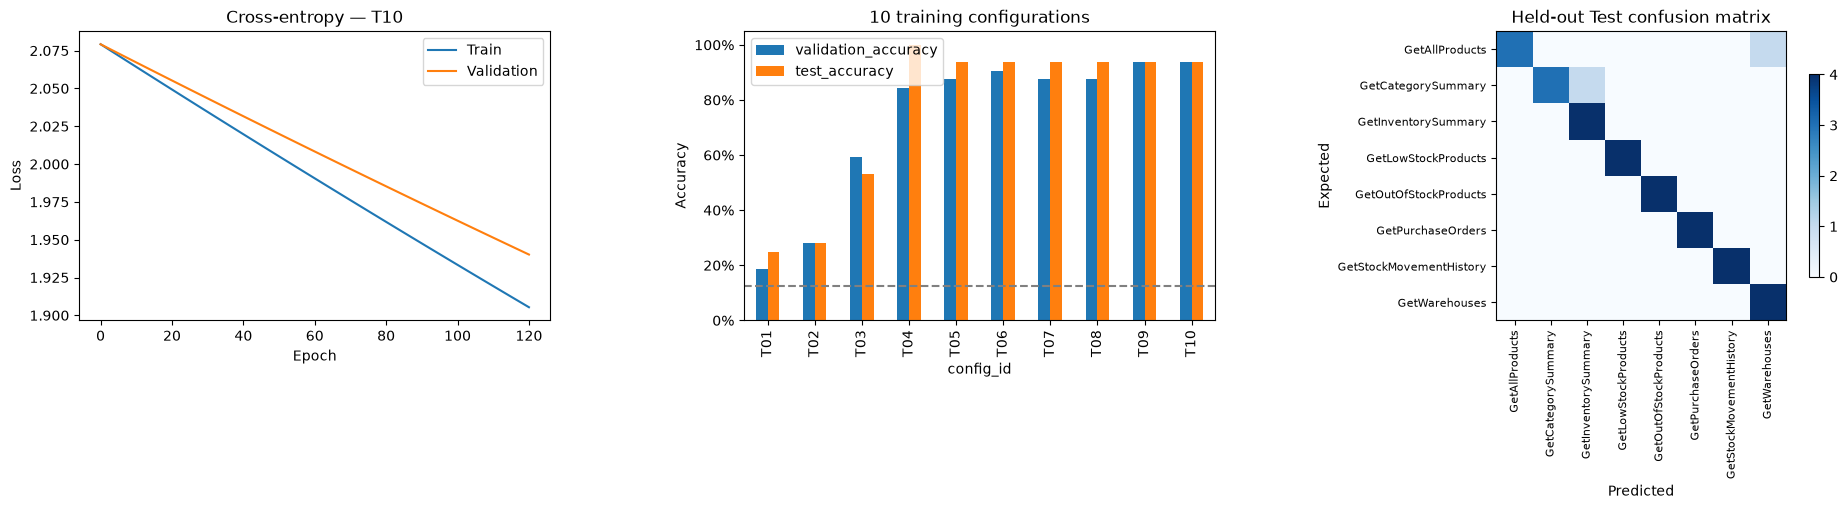

In [5]:
from matplotlib.ticker import PercentFormatter
selected_epochs = training_epochs[training_epochs.config_id == selected_id]
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
axes[0].plot(selected_epochs.epoch, selected_epochs.train_loss, label="Train")
axes[0].plot(selected_epochs.epoch, selected_epochs.validation_loss, label="Validation")
axes[0].set(title=f"Cross-entropy — {selected_id}", xlabel="Epoch", ylabel="Loss")
axes[0].legend()
training_results.plot.bar(x="config_id", y=["validation_accuracy","test_accuracy"], ax=axes[1])
axes[1].axhline(training_meta["baselineTestAccuracy"], color="gray", linestyle="--", label="Baseline")
axes[1].set(title="10 training configurations", ylabel="Accuracy", ylim=(0,1.05))
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
selected_event = training_test_events[training_test_events.configId == selected_id].iloc[0]
labels = list(selected_event.labels)
image_plot = axes[2].imshow(selected_event.confusionMatrix, cmap="Blues")
axes[2].set(title="Held-out Test confusion matrix", xlabel="Predicted", ylabel="Expected")
axes[2].set_xticks(range(len(labels)), labels, rotation=90, fontsize=8)
axes[2].set_yticks(range(len(labels)), labels, fontsize=8)
fig.colorbar(image_plot, ax=axes[2], shrink=.7)
plt.tight_layout()
fig.savefig(training_run / "training_comparison.png", dpi=160, bbox_inches="tight")
plt.show()


### A.5. Nhận xét và hạn chế

- Đối chiếu loss/accuracy theo epoch và giữa cấu hình; cấu hình ít epoch là đối chứng thiếu huấn luyện.
- Cấu hình có Test cao nhất không tự động là cấu hình được chọn: quyết định dùng Validation đã được khóa trước Test.
- Đây là mô hình phụ chọn tên read tool, chưa trích xuất arguments, chưa tích hợp vào AI Assistant production và chưa fine-tune LLM.
- Dataset câu mẫu nhỏ, không phải log người dùng thật; cần dữ liệu độc lập lớn hơn, kiểm tra câu ngoài phạm vi và cơ chế từ chối khi triển khai.
- File model, manifest chia dữ liệu, log Training/Test và dự đoán từng mẫu được giữ trong thư mục của lượt chạy in ở trên.

## Phần B — Kiểm thử MCP C# và PostgreSQL thật


### B.1. Đọc snapshot PostgreSQL thật và kiểm tra dữ liệu

In [6]:
db_ready = cases_ready = results_ready = False
rows = []
# Nhập từng trường; không cần tự ghép DSN hoặc đưa mật khẩu vào code.
connection = {
    "host": ask_text("PostgreSQL host [localhost]: ").strip() or "localhost",
    "port": int(ask_text("PostgreSQL port [5432]: ").strip() or "5432"),
    "dbname": ask_text("Tên database hiện có (cùng DB với API/MCP): ").strip(),
    "user": ask_text("PostgreSQL username: ").strip(),
}
if not connection["dbname"] or not connection["user"]:

    raise ValueError("Tên database và username không được bỏ trống.")
if not (connection["dbname"].startswith("test_") or connection["dbname"].endswith("_tests")):
    while not (connection["dbname"].startswith("test_") or connection["dbname"].endswith("_tests")):
        print("Chỉ dùng database kiểm thử có tên bắt đầu bằng test_ hoặc kết thúc bằng _tests.")
        connection["dbname"] = ask_text("Database kiểm thử: ").strip()
connection["password"] = ask_secret("PostgreSQL password (ẩn): ")
db = None
rows = []
try:
    try:
        db = psycopg.connect(**connection, row_factory=dict_row,
                             autocommit=True, connect_timeout=5)
    except psycopg.Error:
        raise RuntimeError(
            "Không kết nối được PostgreSQL. Kiểm tra service, host, port, "
            "tên database, username và password."
        ) from None
    finally:
        connection.clear()

    db.execute("BEGIN TRANSACTION ISOLATION LEVEL REPEATABLE READ READ ONLY")
    db.execute(sql.SQL("SET LOCAL search_path TO {}").format(sql.Identifier(SCHEMA)))
    rows = db.execute("""
        SELECT p.id, p.sku, p.name, p.min_stock,
               COALESCE(i.quantity, 0) AS quantity
        FROM products p
        JOIN categories c ON c.id = p.category_id
        LEFT JOIN inventory i ON i.product_id = p.id
        WHERE p.is_active
        ORDER BY p.id
    """).fetchall()
finally:
    if db is not None:
        db.close()

assert rows, "Database chưa có sản phẩm active. Chuẩn bị dữ liệu kiểm thử rồi chạy lại."
assert len({r["sku"] for r in rows}) == len(rows), "SKU không duy nhất"
assert all(r["quantity"] >= 0 for r in rows), "Tồn âm"
products = pd.DataFrame(rows)
print("Số sản phẩm active đọc từ PostgreSQL:", len(products))
display(products)

db_ready = True


Số sản phẩm active đọc từ PostgreSQL: 32


,id,sku,name,min_stock,quantity
0,1,SP001,Logitech MX Master 3S,10,0
1,2,SP002,Logitech MX Keys S,10,0
2,3,SP003,Keychron K2 Keyboard,10,0
3,4,SP004,Razer DeathAdder V3,10,0
4,5,SP005,Dell P2425H Monitor,10,0
5,6,SP006,LG 27UP850 Monitor,10,0
6,7,SP007,ASUS ProArt PA278QV,10,6
7,8,SP008,Intel NUC Mini PC,10,0
8,9,SP009,Samsung 990 PRO 1TB SSD,10,0
9,10,SP010,Samsung T7 Shield 1TB,10,0


### B.2. Đăng nhập và khám phá MCP thật
Không in hoặc lưu mật khẩu/token. Lỗi HTTP không được biến thành kết quả mô phỏng.

In [7]:
mcp_ready = cases_ready = results_ready = False
require_step("db_ready", "Chạy thành công ô đọc PostgreSQL trước khi đăng nhập MCP.")
# Kiểm tra process trước khi yêu cầu nhập tài khoản.
try:
    with urlopen(API + "/health/ready", timeout=5) as response:
        if response.status != 200:
            raise RuntimeError("API chưa ready")
except (HTTPError, URLError, TimeoutError):
    raise RuntimeError(
        f"API chưa sẵn sàng tại {API}. Chạy API và MCP theo README, "
        "kiểm tra DB/migrations rồi chạy lại ô này."
    ) from None
token = None
def api(path, payload=None):
    headers = {"Content-Type": "application/json"}
    if token:
        headers["Authorization"] = "Bearer " + token
    data = None if payload is None else json.dumps(payload).encode()
    request = Request(API + path, data=data, headers=headers)
    try:
        with urlopen(request, timeout=135) as response:
            return json.load(response)
    except HTTPError as exc:
        raise RuntimeError(f"API trả HTTP {exc.code}; kiểm tra quyền/cấu hình/log server") from None
    except (URLError, TimeoutError):
        raise RuntimeError("API không phản hồi; kiểm tra process và endpoint") from None
username = ask_text("Username Admin/Staff: ")
password = ask_secret("Password (ẩn): ")
try:
    login = api("/api/auth/login", {"username": username, "password": password})
    token = login["accessToken"]
finally:
    password = None
    login = None
status = api("/api/mcp/status")
assert status["connected"], "MCP chưa kết nối"
tools = api("/api/mcp/tools")
available = {t["name"] for t in tools}
required = {"GetAllProducts", "GetProductById", "GetProductBySku", "GetLowStockProducts", "GetOutOfStockProducts"}
assert required <= available, "Thiếu tool cần thiết"
print("MCP connected; số tool khám phá:", len(available))

mcp_ready = True


MCP connected; số tool khám phá: 30


### B.3. Mười bộ tham số và kết quả mong đợi
Giá trị mong đợi được tính từ snapshot SQL, không hardcode 32 sản phẩm. Nếu dữ liệu thay đổi đồng thời hoặc API dùng DB khác, phép so sánh có thể thất bại.

In [8]:
cases_ready = results_ready = False
require_step("db_ready", "Ô PostgreSQL chưa thành công; chưa có snapshot để tạo cấu hình.")
require_step("mcp_ready", "Ô kết nối API/MCP chưa thành công; khởi động dịch vụ rồi chạy lại bước đó.")
first = rows[0]
all_ids = {r["id"] for r in rows}
cases = []
for size in (5, 10, 20, 100):
    cases.append((f"PAGE-{size}", "GetAllProducts", {"page":1,"pageSize":size}, "page", all_ids))
for threshold in (0, 5, 20):
    ids = {r["id"] for r in rows if r["quantity"] < threshold}
    cases.append((f"LOW-{threshold}", "GetLowStockProducts", {"threshold":threshold,"page":1,"pageSize":100}, "page", ids))
cases.extend([
    ("OUT", "GetOutOfStockProducts", {"page":1,"pageSize":100}, "page", {r["id"] for r in rows if r["quantity"] == 0}),
    ("ID", "GetProductById", {"id":first["id"]}, "single", {first["id"]}),
    ("SKU", "GetProductBySku", {"sku":first["sku"]}, "single", {first["id"]}),
])
assert len(cases) == 10
display(pd.DataFrame([{"case":c[0],"tool":c[1],"arguments":json.dumps(c[2]),"expected_total":len(c[4])} for c in cases]))

cases_ready = True


,case,tool,arguments,expected_total
0,PAGE-5,GetAllProducts,"{""page"": 1, ""pageSize"": 5}",32
1,PAGE-10,GetAllProducts,"{""page"": 1, ""pageSize"": 10}",32
2,PAGE-20,GetAllProducts,"{""page"": 1, ""pageSize"": 20}",32
3,PAGE-100,GetAllProducts,"{""page"": 1, ""pageSize"": 100}",32
4,LOW-0,GetLowStockProducts,"{""threshold"": 0, ""page"": 1, ""pageSize"": 100}",0
5,LOW-5,GetLowStockProducts,"{""threshold"": 5, ""page"": 1, ""pageSize"": 100}",24
6,LOW-20,GetLowStockProducts,"{""threshold"": 20, ""page"": 1, ""pageSize"": 100}",29
7,OUT,GetOutOfStockProducts,"{""page"": 1, ""pageSize"": 100}",24
8,ID,GetProductById,"{""id"": 1}",1
9,SKU,GetProductBySku,"{""sku"": ""SP001""}",1


### B.4. Thực thi thật và đối chiếu
Kiểm tra trạng thái, execution ID, tổng số, ID sản phẩm và số tồn. Với phân trang, duyệt toàn bộ trang để so sánh tập ID, không phụ thuộc thứ tự sắp xếp/collation của PostgreSQL. Dừng khi tool lỗi; không tạo output thay thế.

In [9]:
results_ready = False
require_step("cases_ready", "Chạy thành công bước tạo 10 cấu hình trước khi thực nghiệm.")
def execute(tool, arguments):
    start = time.perf_counter()
    result = api(f"/api/mcp/tools/{tool}/execute", {"arguments":arguments})
    wall_ms = round((time.perf_counter()-start)*1000, 2)
    assert result["status"] == "Succeeded" and not result["isError"], f"Tool lỗi: {tool}, status={result.get('status')}"
    assert result["executionId"] > 0
    output = result["output"]
    assert not output.get("isError", False)
    value = output.get("structuredContent")
    if value is None:
        texts = [x["text"] for x in output.get("content", []) if x.get("type") == "text"]
        assert len(texts) == 1, "Không tìm thấy output JSON duy nhất"
        value = json.loads(texts[0])
    return result, value, wall_ms

run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
evidence, results = [], []
stock = {r["id"]:r["quantity"] for r in rows}
for case_id, tool, arguments, kind, expected_ids in cases:
    collected = []
    page = 1
    execution_ids = []
    wall_total = server_total = 0
    while True:
        args = dict(arguments)
        if kind == "page": args["page"] = page
        record, value, wall_ms = execute(tool, args)
        evidence.append({"case":case_id,"arguments":args,"execution":record,"clientWallMs":wall_ms})
        execution_ids.append(record["executionId"])
        wall_total += wall_ms
        server_total += record["durationMs"]
        if kind == "single":
            batch = [value]
        else:
            assert value["totalCount"] == len(expected_ids), f"{case_id}: SQL/MCP khác tổng"
            assert value["page"] == page and value["pageSize"] == args["pageSize"]
            batch = value["items"]
            assert len(batch) == min(args["pageSize"], max(0,len(expected_ids)-(page-1)*args["pageSize"]))
        for item in batch:
            assert item["id"] in expected_ids, f"{case_id}: sai sản phẩm"
            assert item["quantity"] == stock[item["id"]], f"{case_id}: sai số tồn"
        collected.extend(item["id"] for item in batch)
        if kind == "single" or page * args["pageSize"] >= len(expected_ids): break
        page += 1
    assert len(collected) == len(set(collected)) and set(collected) == expected_ids
    results.append({"case":case_id,"tool":tool,"arguments":json.dumps(arguments),"expectedTotal":len(expected_ids),"actualTotal":len(collected),"calls":len(execution_ids),"executionIds":json.dumps(execution_ids),"serverDurationMs":server_total,"clientWallMs":round(wall_total,2),"comparison":"PASS","source":"REAL_MCP_POSTGRESQL"})
summary = pd.DataFrame(results)
display(summary)
assert len(summary) == 10

results_ready = True


,case,tool,arguments,expectedTotal,actualTotal,calls,executionIds,serverDurationMs,clientWallMs,comparison,source
0,PAGE-5,GetAllProducts,"{""page"": 1, ""pageSize"": 5}",32,32,7,"[13, 14, 15, 16, 17, 18, 19]",87,356.32,PASS,REAL_MCP_POSTGRESQL
1,PAGE-10,GetAllProducts,"{""page"": 1, ""pageSize"": 10}",32,32,4,"[20, 21, 22, 23]",29,135.07,PASS,REAL_MCP_POSTGRESQL
2,PAGE-20,GetAllProducts,"{""page"": 1, ""pageSize"": 20}",32,32,2,"[24, 25]",20,80.33,PASS,REAL_MCP_POSTGRESQL
3,PAGE-100,GetAllProducts,"{""page"": 1, ""pageSize"": 100}",32,32,1,[26],10,43.50,PASS,REAL_MCP_POSTGRESQL
4,LOW-0,GetLowStockProducts,"{""threshold"": 0, ""page"": 1, ""pageSize"": 100}",0,0,1,[27],9,37.67,PASS,REAL_MCP_POSTGRESQL
5,LOW-5,GetLowStockProducts,"{""threshold"": 5, ""page"": 1, ""pageSize"": 100}",24,24,1,[28],9,37.78,PASS,REAL_MCP_POSTGRESQL
6,LOW-20,GetLowStockProducts,"{""threshold"": 20, ""page"": 1, ""pageSize"": 100}",29,29,1,[29],8,37.15,PASS,REAL_MCP_POSTGRESQL
7,OUT,GetOutOfStockProducts,"{""page"": 1, ""pageSize"": 100}",24,24,1,[30],10,40.75,PASS,REAL_MCP_POSTGRESQL
8,ID,GetProductById,"{""id"": 1}",1,1,1,[31],4,30.95,PASS,REAL_MCP_POSTGRESQL
9,SKU,GetProductBySku,"{""sku"": ""SP001""}",1,1,1,[32],4,30.16,PASS,REAL_MCP_POSTGRESQL


### B.5. Biểu đồ và lưu bằng chứng
Thời gian là tổng của các lời gọi cần để đọc hết dữ liệu trong từng cấu hình. Đây là một lượt quan sát, chưa phải benchmark. Chỉ xuất sau khi toàn bộ ca đạt; không xuất token hoặc thông tin kết nối.

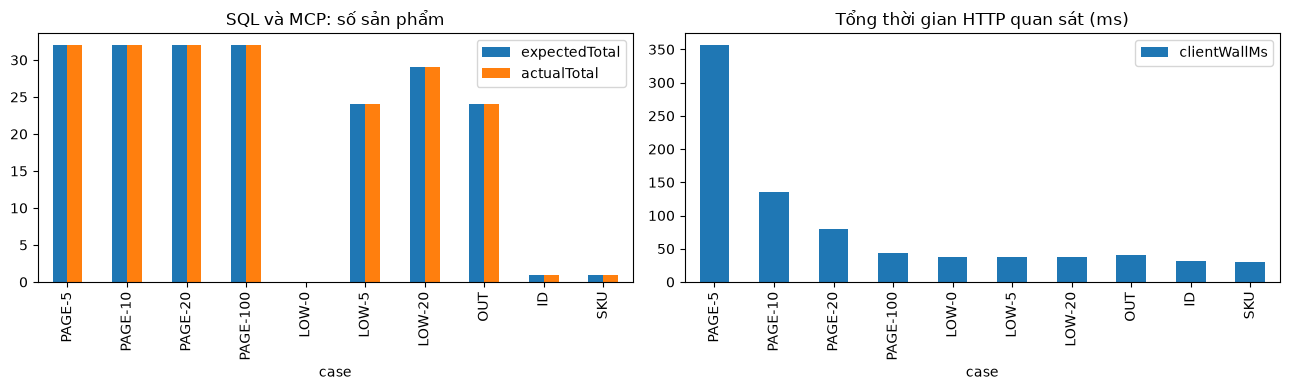

Đã lưu bằng chứng: /Users/minh/MCP_C#/AI-Smart-Inventory/support/experiments/outputs/20261121T120616009173Z


In [10]:
require_step("results_ready", "Chưa có đủ kết quả đạt của 10 cấu hình. Xử lý lỗi ở bước thực nghiệm trước.")
fig, axes = plt.subplots(1, 2, figsize=(13,4))
summary.plot.bar(x="case", y=["expectedTotal","actualTotal"], ax=axes[0], title="SQL và MCP: số sản phẩm")
summary.plot.bar(x="case", y="clientWallMs", ax=axes[1], title="Tổng thời gian HTTP quan sát (ms)")
plt.tight_layout()
plt.show()
# Use the same experiment folder as Part A, including when the kernel starts at the repository root.
if not (experiment_dir / "MCP_CSharp_Inventory_Experiments.ipynb").is_file():
    raise RuntimeError("Chạy ô A.1 trước để xác định thư mục notebook và data.")
out = experiment_dir / "outputs" / run_id
out.mkdir(parents=True, exist_ok=False)
summary.to_csv(out / "real_experiment_results.csv", index=False)
products.to_csv(out / "real_inventory_snapshot.csv", index=False)
(out / "real_execution_log.json").write_text(json.dumps({"runId":run_id,"source":"REAL_MCP_POSTGRESQL","schema":SCHEMA,"serverName":status.get("serverName"),"serverVersion":status.get("serverVersion"),"executions":evidence},ensure_ascii=False,indent=2),encoding="utf-8")
print("Đã lưu bằng chứng:", out)


### B.6. Nhận xét và cải tiến sau khi chạy
- Ghi cấu hình nào đạt/chưa đạt và đối chiếu với log thực tế. Không điền kết quả trước khi chạy.
- Nhận xét ảnh hưởng pageSize tới số lời gọi và tổng thời gian; tránh suy ra tốc độ tuyệt đối từ một lần chạy.
- Giải thích ngưỡng tồn thấp theo điều kiện quantity < threshold.
- Nếu so sánh thất bại: kiểm tra API/MCP/SQL cùng DB/schema và có thao tác thay đổi dữ liệu đồng thời hay không.
- Phạm vi chưa kiểm tra: thao tác ghi, phân quyền, timeout, nhiều kho và hiểu ngôn ngữ tự nhiên của LLM. Các tình huống đó cần bộ thử riêng.
- Bộ này đọc dữ liệu đã tồn tại trong PostgreSQL; không cung cấp dump DB hoặc tự tạo 32 sản phẩm.


### B.7. Test mô hình đã huấn luyện qua MCP thật
Chọn cố định câu Test đầu tiên của mỗi nhãn (không chọn theo việc dự đoán đúng). Mô hình chỉ chọn tool; tám tool đọc dưới đây dùng arguments mặc định. Backend vẫn kiểm tra quyền. Phân biệt `routingCorrect` với trạng thái thực thi tool: gọi thành công không đồng nghĩa phân loại đúng.


In [11]:
require_step("results_ready", "Chạy xong các ca MCP trực tiếp trước khi kiểm tra routing.")
allowed_routing_tools = {"GetAllProducts","GetLowStockProducts","GetOutOfStockProducts","GetInventorySummary","GetStockMovementHistory","GetCategorySummary","GetWarehouses","GetPurchaseOrders"}
selected_predictions = training_predictions[training_predictions.config_id == selected_id]
assert set(selected_predictions.predicted_tool) <= allowed_routing_tools <= available
routing_rows, routing_evidence = [], []
for expected_tool, group in selected_predictions.groupby("expected_tool", sort=True):
    row = group.iloc[0]
    record, value, wall_ms = execute(row.predicted_tool, {})
    correct = row.predicted_tool == expected_tool
    routing_rows.append({"id":row.id,"question":row.text,"expectedTool":expected_tool,"predictedTool":row.predicted_tool,"routingCorrect":correct,"executionId":record["executionId"],"status":record["status"],"serverDurationMs":record["durationMs"]})
    routing_evidence.append({"phase":"test_routing_mcp","trainingRunId":training_meta["runId"],"selectedConfig":selected_id,"id":row.id,"expectedTool":expected_tool,"predictedTool":row.predicted_tool,"routingCorrect":correct,"execution":record,"clientWallMs":wall_ms})
routing_summary = pd.DataFrame(routing_rows)
assert len(routing_summary) == 8 and routing_summary.status.eq("Succeeded").all()
routing_summary.to_csv(training_run / "routing_mcp_results.csv", index=False)
(training_run / "routing_mcp_test_log.jsonl").write_text("\n".join(json.dumps(item,ensure_ascii=False) for item in routing_evidence)+"\n", encoding="utf-8")
display(routing_summary)
print("Tỷ lệ chọn đúng tool trên 8 câu tích hợp cố định:", f"{routing_summary.routingCorrect.mean():.2%}")
print("Đây là tập con kiểm tra kết nối, không thay cho 32 câu Test ở phần A.")


,id,question,expectedTool,predictedTool,routingCorrect,executionId,status,serverDurationMs
0,I01-17,Cho xem tất cả mặt hàng đang hoạt động,GetAllProducts,GetAllProducts,True,33,Succeeded,13
1,I06-17,Tôi cần tổng số lượng của mỗi danh mục,GetCategorySummary,GetCategorySummary,True,34,Succeeded,14
2,I04-17,Tóm tắt tổng số sản phẩm và tổng tồn,GetInventorySummary,GetInventorySummary,True,35,Succeeded,37
3,I02-17,Liệt kê những sản phẩm gần hết hàng,GetLowStockProducts,GetLowStockProducts,True,36,Succeeded,19
4,I03-17,Liệt kê mặt hàng đã hết sạch,GetOutOfStockProducts,GetOutOfStockProducts,True,37,Succeeded,12
5,I08-17,Xem lại các đơn mua đã tạo trong hệ thống,GetPurchaseOrders,GetPurchaseOrders,True,38,Succeeded,23
6,I05-17,Tôi muốn xem lịch sử giao dịch hàng hóa,GetStockMovementHistory,GetStockMovementHistory,True,39,Succeeded,17
7,I07-17,Xem tên và mã những kho hiện có,GetWarehouses,GetWarehouses,True,40,Succeeded,14


Tỷ lệ chọn đúng tool trên 8 câu tích hợp cố định: 100.00%
Đây là tập con kiểm tra kết nối, không thay cho 32 câu Test ở phần A.


## Kết luận thực nghiệm

Bài có dataset và tham số huấn luyện rõ ràng, log Training từng epoch, log Test từng cấu hình, dự đoán từng câu, biểu đồ, model lưu được và log thực thi MCP/PostgreSQL thật. Không gọi log API là log Training. Khi nộp bài, kèm thư mục data, log của đúng trainingRunId và báo cáo, đồng thời nêu rõ dataset câu hỏi là dữ liệu mẫu.
